# Lab 2 — Artificial Neurons (Perceptron, Bias, Activations)

This lab builds intuition for **artificial neurons**, focusing on:

- A manual perceptron for the AND logic gate,
- How **bias** shifts a decision boundary,
- Implementing and plotting **activation functions**,
- Comparing **activations** within a small Keras model,
- A short **reflection** tying it together.

**Workflow note:** Work directly in Colab with GPU off (CPU is fine for Week 3). Commit back to your own GitHub repo frequently via **File → Save a copy to GitHub**.


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/username/repo/blob/main/path-to-file)
**Note:** Replace `username`, `repo`, and `path-to-file` above with your own GitHub username, repository name, and the exact path to this file in your repo.


## B.1 Manual Perceptron (NumPy)


In [1]:
# Goal: implement a single perceptron to model the AND logic gate.
# Instructions:
# 1) Import NumPy.
# 2) Implement a step(z) activation that returns 1 where z >= 0 and 0 otherwise.
# 3) Create input data X with four rows: [0,0], [0,1], [1,0], [1,1]. dtype float32.
# 4) Create target labels y = [0, 0, 0, 1] as int32.
# 5) Choose weights w (length-2 NumPy array) and a bias scalar b for AND logic.
#    Hint: equal weights (e.g., 1.0, 1.0) and a negative bias (e.g., -1.5) will require both inputs to be 1.
# 6) Compute z = X @ w + b   (vectorized for all 4 samples).
# 7) Compute y_hat = step(z).
# 8) Print z, y_hat, and y to verify correctness.
#
# Expected output:
# - z: an array of four values (weighted sums), with only the last one >= 0
# - y_hat: [0 0 0 1]
# - y:     [0 0 0 1]

# Write your code below.
import numpy as np

def step(z):
    return np.where(z >= 0, 1, 0)

X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=np.float32)
y = np.array([0,0,0,1], dtype=np.int32)
w = np.array([1.0, 1.0], dtype=np.float32)
b = -1.5

z = X @ w + b
y_hat = step(z)
print("z:", z)
print("y_hat:", y_hat)
print("y:", y)

z: [-1.5 -0.5 -0.5  0.5]
y_hat: [0 0 0 1]
y: [0 0 0 1]


## B.2 Bias Intuition


In [2]:
# Goal: observe how changing the bias shifts the decision boundary.
# Instructions:
# 1) Reuse your X, w from B.1 (or recreate them quickly).
# 2) Create a list of bias values, e.g., [-2.0, -1.5, -1.0, -0.5, 0.0].
# 3) For each bias in the list, compute y_hat = step(X @ w + b) and print the result.
# 4) Briefly note which biases make the perceptron stricter or looser (in a markdown cell below).
#
# Expected output:
# - Each line should show the bias value and predicted outputs (array of length 4).
# - Example:
#   b=-2.0: [0 0 0 0]
#   b=-1.5: [0 0 0 1]
#   b=-1.0: [0 0 1 1]
#   ...
# - This should demonstrate how lowering the bias makes it easier for the perceptron to activate.

# Write your code below.
biases = [-2.0, -1.5, -1.0, -0.5, 0.0]
for b in biases:
    y_hat = step(X @ w + b)
    print(f"b={b}: {y_hat}")

b=-2.0: [0 0 0 1]
b=-1.5: [0 0 0 1]
b=-1.0: [0 1 1 1]
b=-0.5: [0 1 1 1]
b=0.0: [1 1 1 1]


## B.3 Activation Functions: Implement & Plot


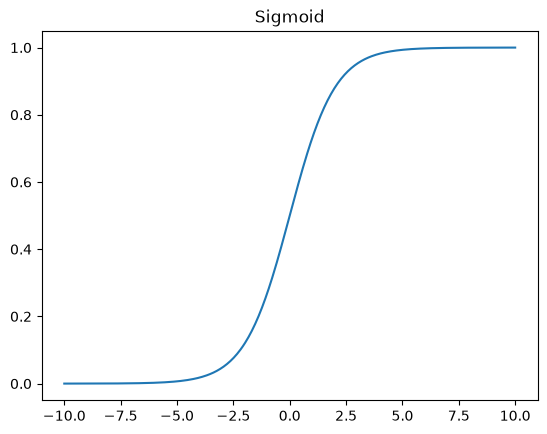

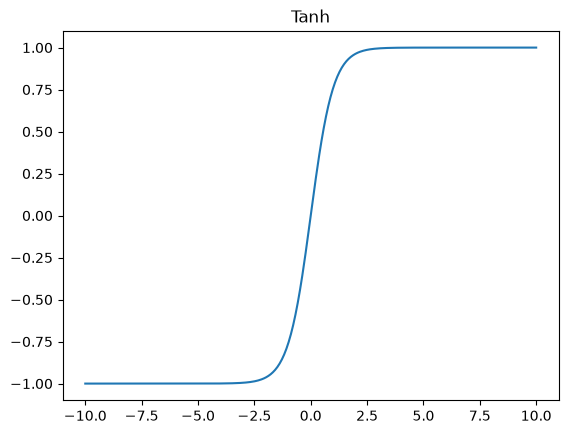

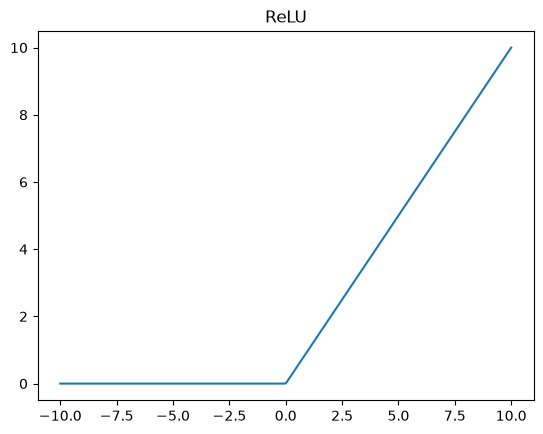

In [3]:
# Goal: implement three activation functions (without importing from ML frameworks) and plot them.
# Instructions:
# 1) Import NumPy and matplotlib.pyplot as plt.
# 2) Implement functions:
#       sigmoid(x) -> 1/(1+exp(-x))
#       tanh(x)    -> use np.tanh(x)
#       relu(x)    -> elementwise max(0, x)
#    Each function should accept scalars or NumPy arrays and return a NumPy array.
# 3) Create an array xs = np.linspace(-10, 10, 400).
# 4) Make three separate plots (one for each activation). Do not customize colors.
# 5) Add simple titles: "Sigmoid", "Tanh", "ReLU".
#
# Expected output:
# - Three plots:
#   1) Sigmoid: S-shaped curve from ~0 to ~1.
#   2) Tanh: S-shaped curve from ~-1 to ~1, crossing at (0,0).
#   3) ReLU: Flat at 0 for x<0, linearly increasing for x>0.

# Write your code below.
import numpy as np
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-np.asarray(x, dtype=np.float64)))

def tanh(x):
    return np.tanh(x)

def relu(x):
    return np.maximum(0, np.asarray(x))

xs = np.linspace(-10, 10, 400)

for name, fn in [("Sigmoid", sigmoid), ("Tanh", tanh), ("ReLU", relu)]:
    plt.figure()
    plt.plot(xs, fn(xs))
    plt.title(name)
    plt.show()

## B.4 Swap Activations in a Keras Model (MNIST)


In [4]:
# Goal: compare the impact of different hidden-layer activations on MNIST with a shallow network.
# Instructions:
# 1) Import TensorFlow/Keras:
#       from tensorflow import keras
#       from tensorflow.keras import layers
# 2) Load MNIST using keras.datasets.mnist.load_data().
# 3) Normalize pixel values to [0,1] and flatten images to vectors of length 784.
# 4) Write a helper function train_with_activation(act: str) that:
#       - Builds a Sequential model: Input(784) -> Dense(128, activation=act) -> Dense(10, activation='softmax')
#       - Compiles with Adam(1e-3), sparse_categorical_crossentropy, metrics=['accuracy']
#       - Fits for a small number of epochs (e.g., epochs=3, batch_size=128, validation_split=0.1)
#       - Evaluates on the test set and returns the test accuracy (float).
# 5) Loop over activations ['sigmoid', 'tanh', 'relu']:
#       - Call the helper for each activation
#       - Print the test accuracy for each
# 6) In a short markdown cell below, summarize what you observe and provide a hypothesis why.
#
# Expected output:
# - Three lines printed (one per activation), e.g.:
#   sigmoid -> test acc: 0.92
#   tanh    -> test acc: 0.94
#   relu    -> test acc: 0.97
# - ReLU is typically highest, but exact numbers will vary.

# Write your code below.
from tensorflow import keras
from tensorflow.keras import layers

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.astype("float32").reshape(-1, 784) / 255.0
x_test = x_test.astype("float32").reshape(-1, 784) / 255.0

def train_with_activation(act):
    model = keras.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(128, activation=act),
        layers.Dense(10, activation='softmax'),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    model.fit(x_train, y_train, epochs=3, batch_size=128, validation_split=0.1, verbose=0)
    _, acc = model.evaluate(x_test, y_test, verbose=0)
    return float(acc)

for act in ['sigmoid', 'tanh', 'relu']:
    acc = train_with_activation(act)
    print(f"{act:8s}-> test acc: {acc:.4f}")

sigmoid -> test acc: 0.9382
tanh    -> test acc: 0.9603
relu    -> test acc: 0.9676


## B.5 Reflection (Short Answer)

- Which activation performed best in your experiment? Did that match your expectation?
ReLU, at 0.9676 and yes
- How does the bias term affect the decision boundary in your perceptron example?
Bias moves the decision boundary. A lower bias means the neuron needs a bigger input to fire. A higher bias makes it fire more easily
- When might you prefer sigmoid, tanh, or ReLU in hidden layers? Explain briefly.
Sigmoid: Use it when the output should be a probability.
Tanh: Use it when you want outputs centered around zero.
ReLU: Use it as the default for hidden layers, because it's fast and trains well.
